# 01 · Comprensión y preparación de datos — Dry Bean Dataset
**Rol:** Data Engineer / Analyst · **Sprint 1** · **Backlog:** PB-01 (ingesta) y PB-02 (calidad de datos)

| Fase CRISP-DM | Dónde en este notebook |
|---|---|
| 2. Comprensión de los datos | Secciones 1 a 6 y 8 |
| 3. Preparación de los datos | Sección 7 |

**TDSP:** el dato crudo queda inmutable en `data/raw/`; lo procesado va a `data/processed/`; las gráficas y reportes a `outputs/reports/`. La lógica reutilizable vive en `src/` y está probada en `tests/`.

In [1]:
import os
from pathlib import Path

# El notebook vive en notebooks/; las rutas del proyecto son relativas a la raíz
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data_loader import load_raw_data
from src.make_dataset import build_datasets
from src.preprocessing import RANDOM_STATE, TEST_SIZE, TARGET_COL
from src.quality import outlier_counts_iqr, quality_summary

REPORTS = Path("outputs/reports")
REPORTS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

## 1. Ingesta (PB-01)
Se descarga de UCI (id=602) la primera vez y se guarda en `data/raw/dry_bean_raw.csv`; las siguientes ejecuciones leen ese CSV.

In [2]:
df = load_raw_data()
assert df.shape == (13611, 17), df.shape   # criterio de aceptación PB-01
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


**Preguntas de la actividad (Paso 3 del laboratorio)**
1. ¿Cuántas columnas tiene? **17** (16 características + `Class`).
2. ¿Variable objetivo? **`Class`** (variedad de frijol).
3. ¿Clasificación o regresión? **Clasificación multiclase** (7 clases).

## 2. Estructura y estadísticas descriptivas

In [3]:
print("Forma:", df.shape)
df.info()

Forma: (13611, 17)
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: f

In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.524,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRatio,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


Las 16 características son numéricas (14 `float64` y 2 `int64`: `Area` y `ConvexArea`, en píxeles). La única columna no numérica es `Class`.

## 3. Nulos y duplicados (PB-02)

In [5]:
nulos = df.isna().sum()
print("Valores nulos por columna:")
print(nulos[nulos > 0] if nulos.any() else "Ninguno: 0 nulos en todas las columnas")
dup_mask = df.duplicated(keep="first")
print("\nFilas duplicadas:", int(dup_mask.sum()))
print("Duplicados por clase:")
print(df.loc[dup_mask, TARGET_COL].value_counts())

Valores nulos por columna:
Ninguno: 0 nulos en todas las columnas

Filas duplicadas: 68
Duplicados por clase:
Class
HOROZ    68
Name: count, dtype: int64


**Decisión técnica:** no hay nulos, así que no se imputa nada. Hay **68 filas duplicadas**, todas de la clase `HOROZ`. Se eliminan para que el modelo no vea la misma observación en train y en test, lo que inflaría las métricas (fuga de datos).

## 4. Variable objetivo

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Proporción (%):
Class
DERMASON    26.05
SIRA        19.37
SEKER       14.89
HOROZ       14.17
CALI        11.98
BARBUNYA     9.71
BOMBAY       3.84
Name: count, dtype: float64


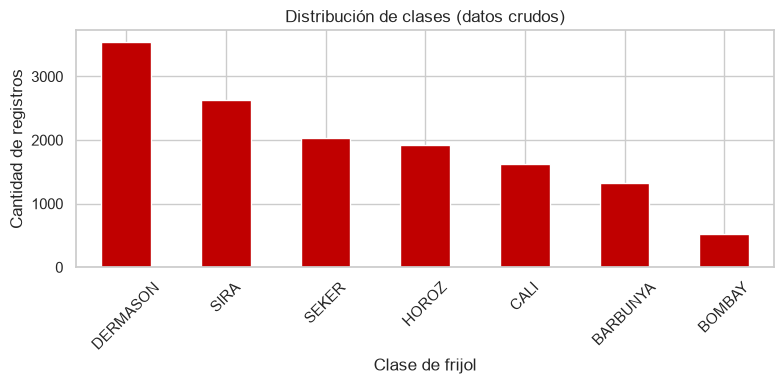

Razón mayoritaria/minoritaria: 6.8


In [6]:
counts = df[TARGET_COL].value_counts()
print(counts)
print("\nProporción (%):")
print((counts / counts.sum() * 100).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
counts.plot(kind="bar", ax=ax, color="#C00000")
ax.set_title("Distribución de clases (datos crudos)")
ax.set_xlabel("Clase de frijol"); ax.set_ylabel("Cantidad de registros")
plt.xticks(rotation=45); plt.tight_layout()
fig.savefig(REPORTS / "distribucion_clases.png", dpi=150)
plt.show()
print("Razón mayoritaria/minoritaria:", round(counts.max() / counts.min(), 1))

**¿Están balanceadas?** No. `DERMASON` (3.546) tiene ~6,8 veces más registros que `BOMBAY` (522). Con clases desbalanceadas el *accuracy* puede ser alto aunque el modelo falle en las clases pequeñas, por eso se prioriza **F1 macro** y se usa `stratify=y` en el split para que train y test conserven las proporciones.

## 5. Outliers y distribuciones

In [7]:
features = df.drop(columns=TARGET_COL)
out = outlier_counts_iqr(features).sort_values(ascending=False)
out_df = pd.DataFrame({"outliers_IQR": out, "porcentaje": (out / len(df) * 100).round(2)})
out_df

,outliers_IQR,porcentaje
Eccentricity,843,6.19
Solidity,778,5.72
ShapeFactor4,767,5.64
MinorAxisLength,569,4.18
Area,551,4.05
ConvexArea,550,4.04
ShapeFactor1,533,3.92
EquivDiameter,526,3.86
Perimeter,500,3.67
AspectRatio,473,3.48


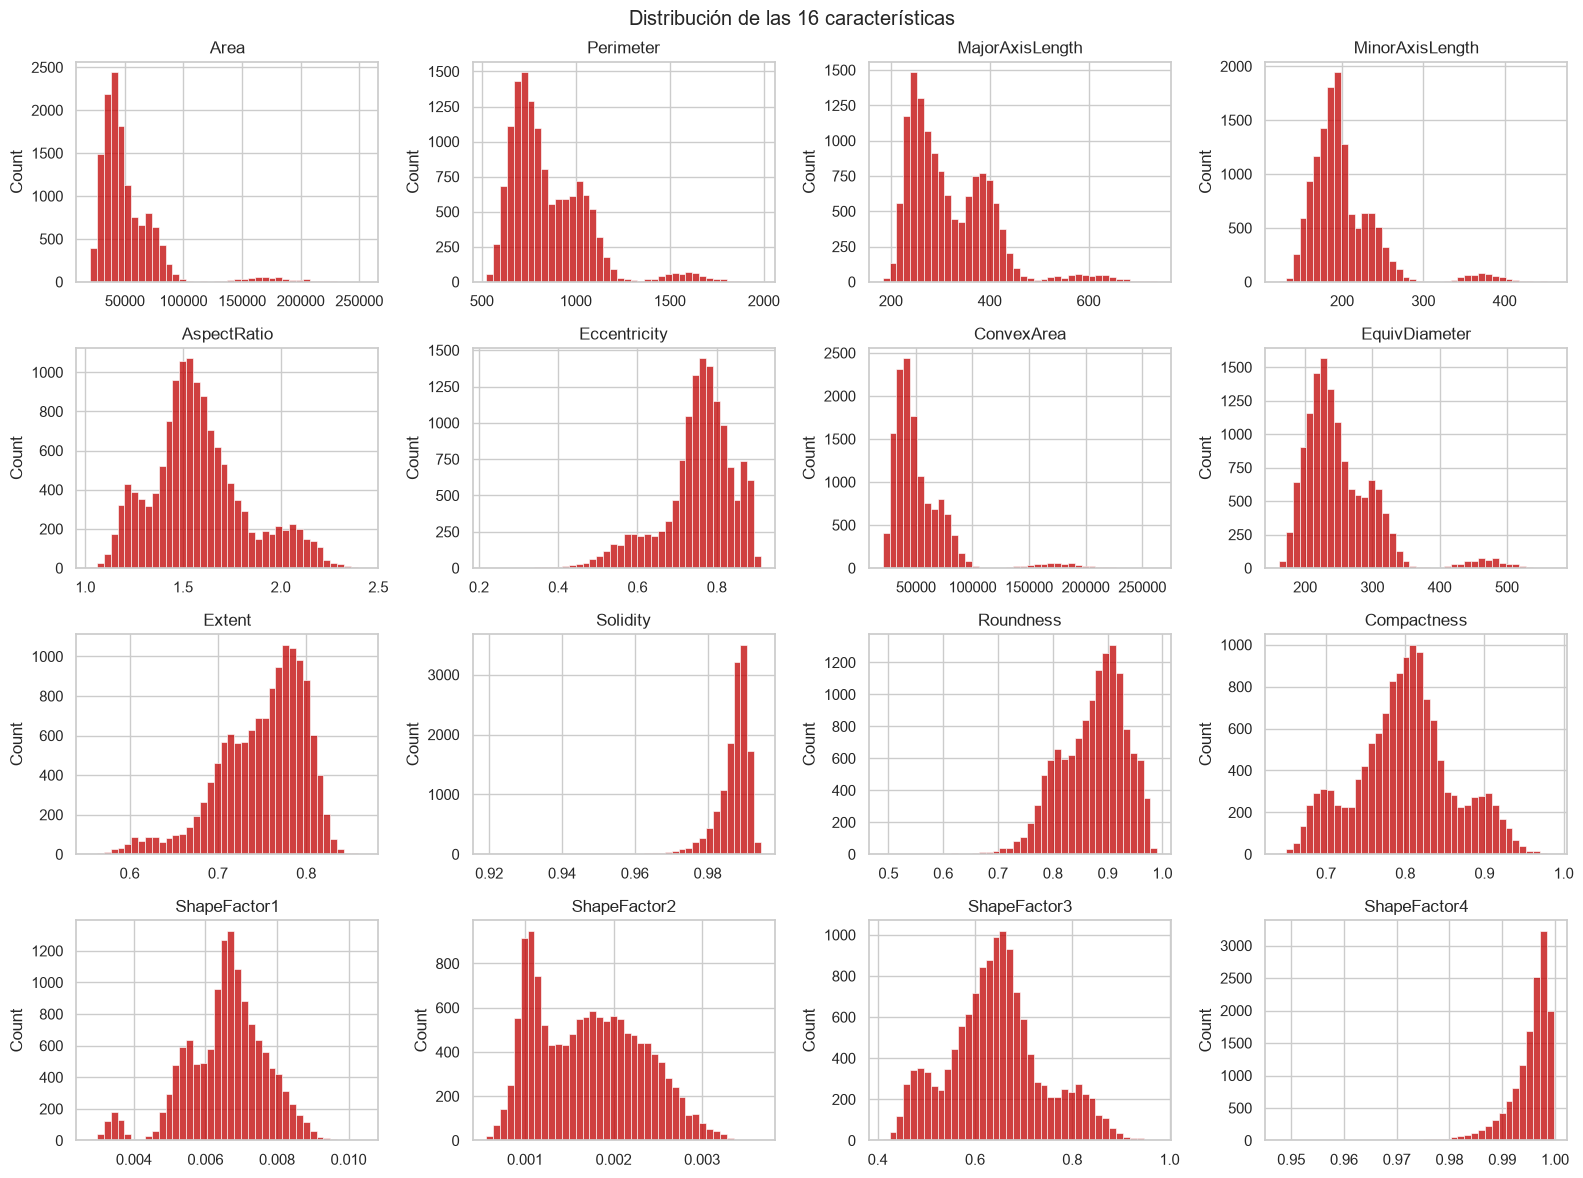

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), features.columns):
    sns.histplot(features[col], bins=40, ax=ax, color="#C00000")
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Distribución de las 16 características")
plt.tight_layout()
fig.savefig(REPORTS / "histogramas_variables.png", dpi=120)
plt.show()

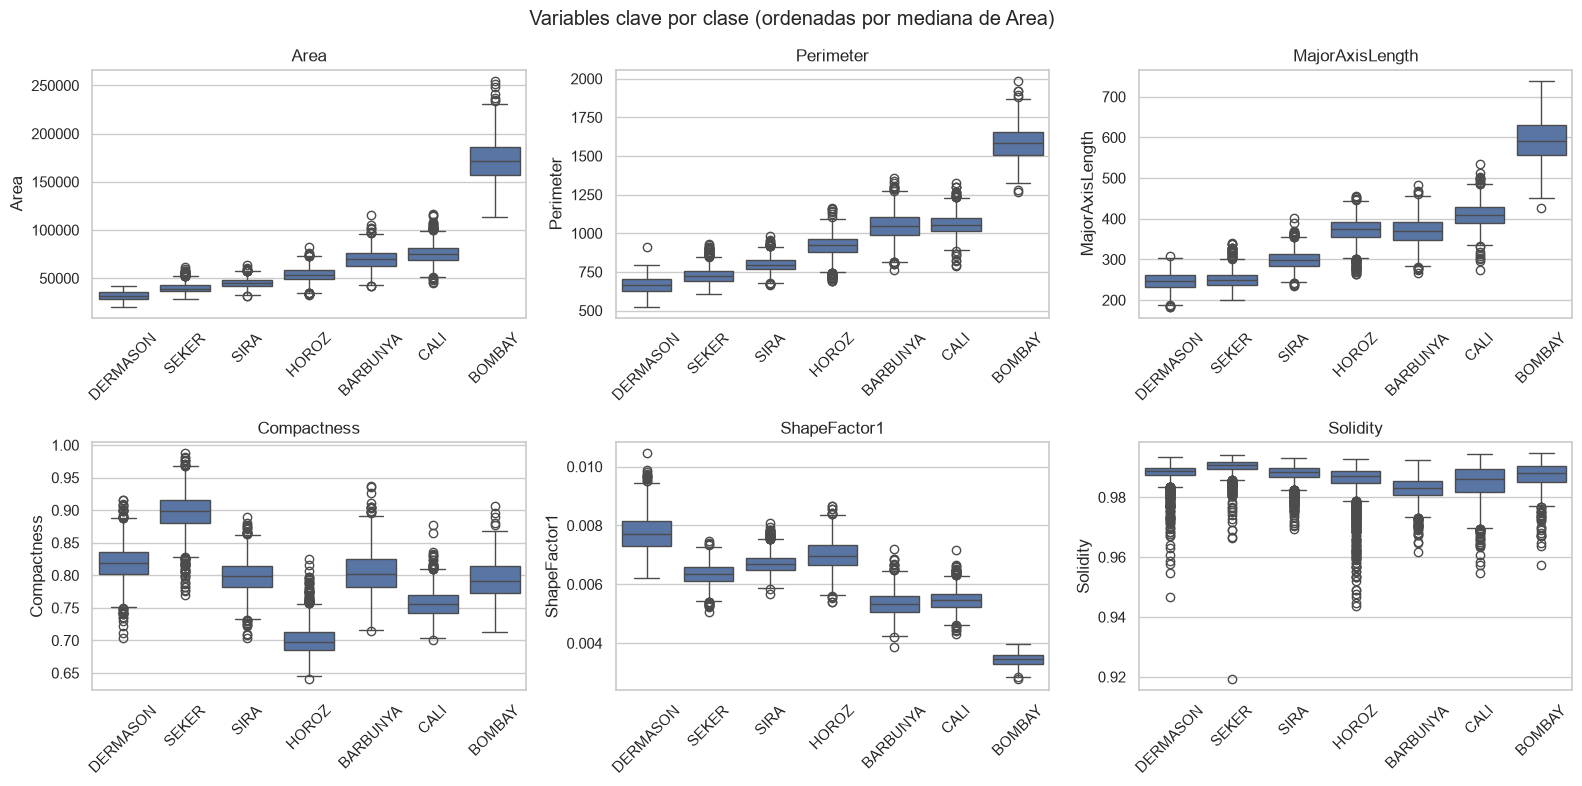

In [9]:
key = ["Area", "Perimeter", "MajorAxisLength", "Compactness", "ShapeFactor1", "Solidity"]
order = df.groupby(TARGET_COL)["Area"].median().sort_values().index
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), key):
    sns.boxplot(data=df, x=TARGET_COL, y=col, order=order, ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
plt.suptitle("Variables clave por clase (ordenadas por mediana de Area)")
plt.tight_layout()
fig.savefig(REPORTS / "boxplots_por_clase.png", dpi=120)
plt.show()

**Lectura:** los outliers por IQR son frecuentes (p. ej. `Eccentricity`, `Solidity`, `ShapeFactor4`). Son mediciones físicas reales de granos, no errores de captura, por eso **no se eliminan**. Los boxplots permiten ver qué clases se separan por tamaño (`Area`, `Perimeter`) y cuáles se solapan y dependen más de la forma.

## 6. Correlaciones

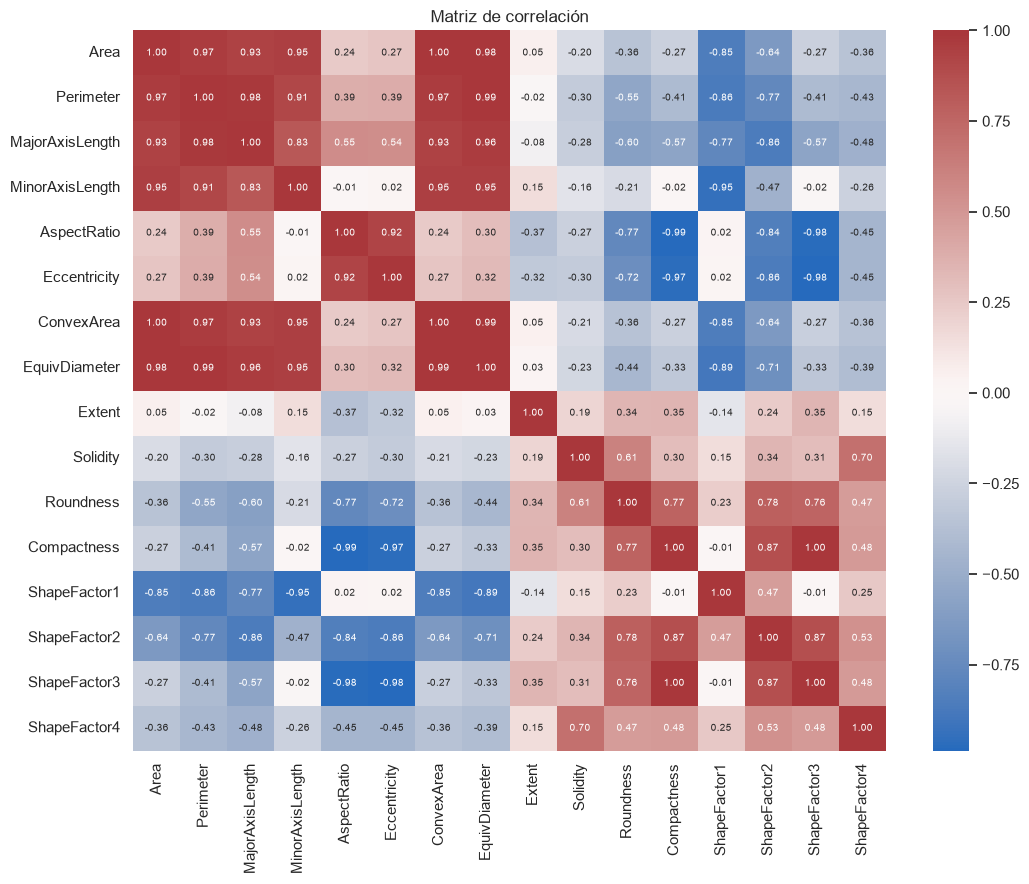

Area           ConvexArea       1.000
Compactness    ShapeFactor3     0.999
EquivDiameter  Perimeter        0.991
AspectRatio    Compactness      0.988
ConvexArea     EquivDiameter    0.985
Area           EquivDiameter    0.985
Eccentricity   ShapeFactor3     0.981
AspectRatio    ShapeFactor3     0.979
dtype: float64

In [10]:
corr = features.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Matriz de correlación")
plt.tight_layout()
fig.savefig(REPORTS / "matriz_correlacion.png", dpi=120)
plt.show()

pairs = corr.abs().where(lambda m: m < 1).stack()
pairs = pairs[[a < b for a, b in pairs.index]].sort_values(ascending=False)
pairs.head(8).round(3)

**Hallazgo para el ML Engineer:** hay colinealidad muy alta, sobre todo entre las variables de tamaño (`Area`–`ConvexArea` ≈ 1,00; `EquivDiameter`–`Perimeter` ≈ 0,99) y entre `Compactness`–`ShapeFactor3` ≈ 1,00. No afecta a Random Forest, pero sí puede volver inestables los coeficientes de la Regresión Logística. No se eliminan variables en el Sprint 1; queda como insumo para el Sprint 2.

## 7. Preparación de datos (CRISP-DM fase 3)

In [11]:
info = build_datasets(df)   # limpia, separa y guarda data/processed/{dry_bean_clean,train,test}.csv
print(info)
print(f"semilla={RANDOM_STATE} · test_size={TEST_SIZE} · estratificado por {TARGET_COL}")

{'filas_crudas': 13611, 'duplicados_eliminados': 68, 'filas_limpias': 13543, 'filas_train': 10834, 'filas_test': 2709}
semilla=42 · test_size=0.2 · estratificado por Class


In [12]:
train = pd.read_csv("data/processed/train.csv")
test = pd.read_csv("data/processed/test.csv")
prop = pd.DataFrame({
    "train_%": (train[TARGET_COL].value_counts(normalize=True) * 100).round(2),
    "test_%": (test[TARGET_COL].value_counts(normalize=True) * 100).round(2),
})
prop["diferencia_pp"] = (prop["train_%"] - prop["test_%"]).abs().round(3)
assert prop["diferencia_pp"].max() < 0.1
prop

,train_%,test_%,diferencia_pp
Class,,,
DERMASON,26.19,26.17,0.02
SIRA,19.47,19.45,0.02
SEKER,14.96,14.99,0.03
HOROZ,13.73,13.73,0.00
CALI,12.04,12.03,0.01
BARBUNYA,9.76,9.78,0.02
BOMBAY,3.86,3.84,0.02


El split **conserva las proporciones de clase** (diferencia máxima < 0,1 puntos porcentuales).

## 8. Resumen de calidad (criterio de aceptación PB-02)

In [13]:
clean_df = pd.read_csv("data/processed/dry_bean_clean.csv")
raw_s = quality_summary(df)
clean_s = quality_summary(clean_df)

resumen = pd.DataFrame({
    "metrica": ["filas", "columnas", "nulos_totales", "duplicados", "outliers_IQR_totales"],
    "datos_crudos": [raw_s["filas"], raw_s["columnas"], raw_s["nulos_totales"], raw_s["duplicados"], int(out.sum())],
    "datos_limpios": [clean_s["filas"], clean_s["columnas"], clean_s["nulos_totales"], clean_s["duplicados"],
                      int(outlier_counts_iqr(clean_df.drop(columns=TARGET_COL)).sum())],
})
resumen.to_csv(REPORTS / "resumen_calidad_datos.csv", index=False)

clases = pd.DataFrame({"crudo": raw_s["clases"], "limpio": clean_s["clases"]})
clases.to_csv(REPORTS / "resumen_clases.csv")
display(resumen)
display(clases)

,metrica,datos_crudos,datos_limpios
0,filas,13611,13543
1,columnas,17,17
2,nulos_totales,0,0
3,duplicados,68,0
4,outliers_IQR_totales,7139,7152


,crudo,limpio
DERMASON,3546,3546
SIRA,2636,2636
SEKER,2027,2027
HOROZ,1928,1860
CALI,1630,1630
BARBUNYA,1322,1322
BOMBAY,522,522


## 9. Conclusiones del Sprint 1
- El dataset **carga sin errores**: 13.611 filas × 17 columnas, 7 clases, sin nulos.
- Se eliminaron **68 duplicados** (todos `HOROZ`) → **13.543 filas limpias**.
- Las clases están **desbalanceadas** (`DERMASON` 3.546 vs. `BOMBAY` 522) → métrica principal F1 macro.
- Hay **colinealidad alta** entre variables de tamaño → tenerlo presente al interpretar la Regresión Logística.
- Split **80/20 estratificado** con semilla 42 guardado en `data/processed/`, listo para el ML Engineer.
- Los datos están listos para el Sprint 2 (modelado y evaluación).